# เจาะลึกข้อมูล Predicting Smartphone Addiction

## tl;dr

Notebook นี้ตรวจคุณภาพข้อมูล, missingness, train–test drift, ความสัมพันธ์กับ target และสร้างโมเดล holdout ขนาดจำกัดเพื่อยืนยันสัญญาณหลัก ผลสรุปเชิงตัวเลขถูกสร้างจากเซลล์ด้านล่างโดยตรง

## Context & Methods

### Key Assumptions

- หนึ่งแถวแทนหนึ่งตัวอย่างอิสระ และ `id` เป็นเพียงตัวระบุ
- ROC AUC เป็น metric หลัก จึงประเมินความสามารถในการจัดอันดับความเสี่ยง
- ผล holdout เป็น diagnostic baseline ไม่ใช่คะแนน cross-validation ขั้นสุดท้าย

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from src.deep_dive import run_analysis

result = run_analysis()
quality = result['summary']['quality']
tables = result['tables']
quality

{'train_rows': 691369,
 'test_rows': 296302,
 'feature_count': 12,
 'numeric_feature_count': 9,
 'categorical_feature_count': 3,
 'target_rate': 0.7094243450313797,
 'target_count_1': 490474,
 'target_count_0': 200895,
 'id_unique_train': True,
 'id_unique_test': True,
 'id_overlap': 0,
 'exact_duplicate_rows_train': 0,
 'duplicate_features_train': 0,
 'duplicate_features_test': 0,
 'train_id_min': 0,
 'train_id_max': 691368,
 'test_id_min': 691369,
 'test_id_max': 987670,
 'holdout_auc_histgb': 0.9565452451817048,
 'three_feature_composite_auc': 0.9107697015799169,
 'mean_missing_features_train': 1.2588935864928859,
 'mean_missing_features_test': 1.2728803720528379}

## Data

### โครงสร้างและ missingness

In [2]:
display(tables['profile'].round(3))
display(tables['validity'].query('invalid_count > 0'))

,feature,dtype,train_missing_pct,test_missing_pct,train_unique,test_unique
0,age,float64,4.184,5.784,18,18
1,daily_screen_time_hours,float64,13.864,11.066,1389,1349
2,social_media_hours,float64,19.381,15.996,721,703
3,gaming_hours,float64,18.343,20.054,401,401
4,work_study_hours,float64,7.452,9.375,600,601
5,sleep_hours,float64,6.434,7.578,451,451
6,notifications_per_day,float64,9.775,11.549,231,231
7,app_opens_per_day,float64,11.674,8.675,166,166
8,weekend_screen_time,float64,16.209,17.110,1437,1404
9,gender,object,4.199,4.796,3,3


,split,feature,invalid_count,invalid_pct


## Results

### สัญญาณตัวเลขที่สัมพันธ์กับ target

,feature,mean_not_addicted,mean_addicted,standardized_mean_diff,univariate_auc_strength,missing_target_rate,present_target_rate
1,daily_screen_time_hours,5.0429,8.7065,1.3462,0.8896,0.7113,0.7091
8,weekend_screen_time,6.8489,10.5587,1.2990,0.8810,0.7107,0.7092
2,social_media_hours,1.3761,2.9195,1.1726,0.8578,0.7094,0.7094
4,work_study_hours,1.8726,2.5696,0.5537,0.6549,0.7106,0.7093
3,gaming_hours,1.1597,1.5821,0.4520,0.6220,0.7105,0.7092
7,app_opens_per_day,97.8714,104.5928,0.1398,0.5409,0.7128,0.7090
5,sleep_hours,6.7223,6.8380,0.0937,0.5270,0.7134,0.7092
6,notifications_per_day,147.0877,145.4061,-0.0255,0.5079,0.7102,0.7093
0,age,26.5829,26.6287,0.0089,0.5023,0.7134,0.7093


/var/folders/v1/cg68bsk14199vygscqcbnz_r0000gn/T/ipykernel_2588/2118923889.py:7: UserWarning: Glyph 3611 (\N{THAI CHARACTER PO PLA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/v1/cg68bsk14199vygscqcbnz_r0000gn/T/ipykernel_2588/2118923889.py:7: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/v1/cg68bsk14199vygscqcbnz_r0000gn/T/ipykernel_2588/2118923889.py:7: UserWarning: Glyph 3633 (\N{THAI CHARACTER MAI HAN-AKAT}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/v1/cg68bsk14199vygscqcbnz_r0000gn/T/ipykernel_2588/2118923889.py:7: UserWarning: Glyph 3610 (\N{THAI CHARACTER BO BAIMAI}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/v1/cg68bsk14199vygscqcbnz_r0000gn/T/ipykernel_2588/2118923889.py:7: UserWarning: Glyph 3607 (\N{THAI CHARACTER THO THAHAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()

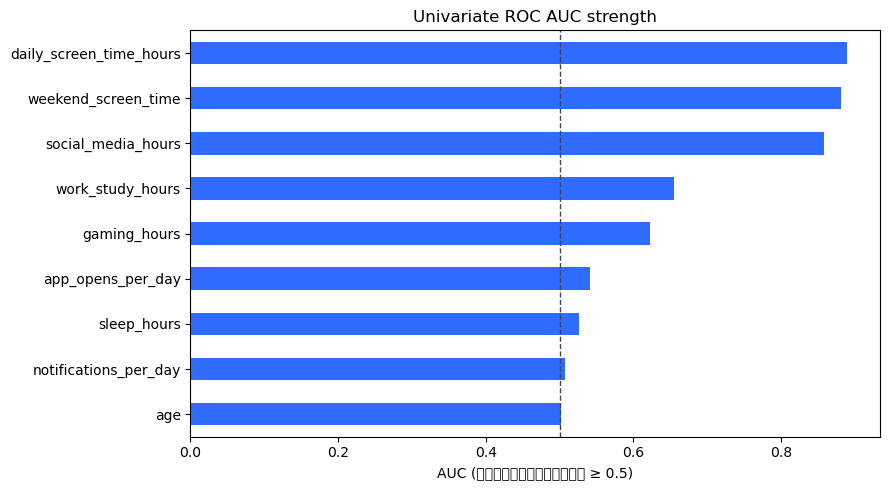

In [3]:
signal = tables['numeric_signal'].copy()
display(signal.round(4))
ax = signal.sort_values('univariate_auc_strength').plot.barh(
    x='feature', y='univariate_auc_strength', legend=False, figsize=(9, 5), color='#2F6BFF')
ax.axvline(0.5, color='#3D4652', linestyle='--', linewidth=1)
ax.set(title='Univariate ROC AUC strength', xlabel='AUC (ปรับทิศทางให้ ≥ 0.5)', ylabel='')
plt.tight_layout(); plt.show()

### Target rate ตาม decile ของตัวแปรหลัก

feature,daily_screen_time_hours,social_media_hours,weekend_screen_time
decile,,,
1,0.2651,0.2496,0.2644
2,0.3104,0.3378,0.3221
3,0.3986,0.4794,0.3962
4,0.5343,0.6319,0.5728
5,0.7234,0.7287,0.7464
6,0.8953,0.8311,0.8680
7,0.9743,0.8998,0.9485
8,0.9947,0.9597,0.9881
9,0.9987,0.9855,0.9980


/var/folders/v1/cg68bsk14199vygscqcbnz_r0000gn/T/ipykernel_2588/1858107095.py:8: UserWarning: Glyph 3588 (\N{THAI CHARACTER KHO KHWAI}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/v1/cg68bsk14199vygscqcbnz_r0000gn/T/ipykernel_2588/1858107095.py:8: UserWarning: Glyph 3656 (\N{THAI CHARACTER MAI EK}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/v1/cg68bsk14199vygscqcbnz_r0000gn/T/ipykernel_2588/1858107095.py:8: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/v1/cg68bsk14199vygscqcbnz_r0000gn/T/ipykernel_2588/1858107095.py:8: UserWarning: Glyph 3605 (\N{THAI CHARACTER TO TAO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/var/folders/v1/cg68bsk14199vygscqcbnz_r0000gn/T/ipykernel_2588/1858107095.py:8: UserWarning: Glyph 3635 (\N{THAI CHARACTER SARA AM}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.sh

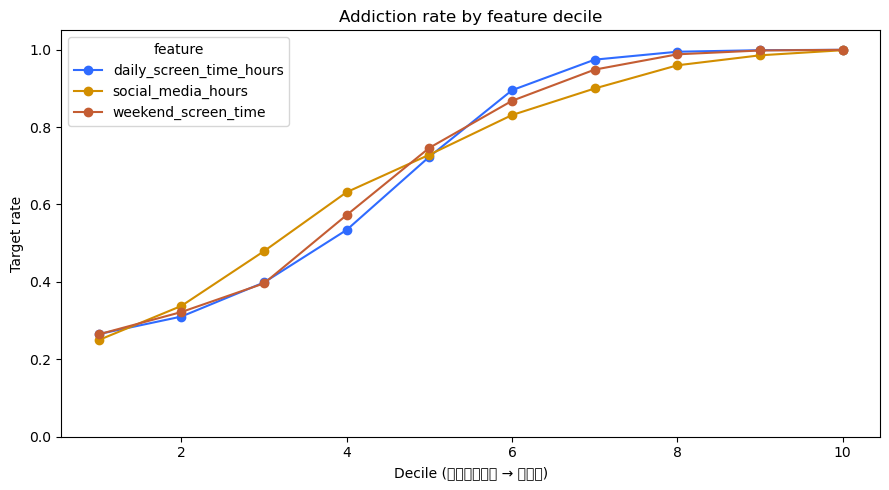

In [4]:
top = tables['binned_target'].query(
    "feature in ['daily_screen_time_hours', 'weekend_screen_time', 'social_media_hours']"
)
pivot = top.pivot(index='decile', columns='feature', values='target_rate')
display(pivot.round(4))
ax = pivot.plot(figsize=(9, 5), marker='o', color=['#2F6BFF', '#D28E00', '#C45D33'])
ax.set(title='Addiction rate by feature decile', xlabel='Decile (ค่าต่ำ → สูง)', ylabel='Target rate', ylim=(0, 1.05))
plt.tight_layout(); plt.show()

### Train–test drift และ missingness

In [5]:
display(tables['drift'].round(5))
display(tables['missing_pattern'].round(4))

,feature,kind,drift_score,ks_statistic,missing_diff_pp
11,academic_work_impact,categorical,0.02284,NaN,2.28409
10,stress_level,categorical,0.01353,NaN,-1.35299
9,gender,categorical,0.00597,NaN,0.59696
2,social_media_hours,numeric,0.00008,0.00229,-3.38493
6,notifications_per_day,numeric,0.00006,0.00402,1.77398
7,app_opens_per_day,numeric,0.00006,0.00266,-2.99867
8,weekend_screen_time,numeric,0.00005,0.00285,0.90105
3,gaming_hours,numeric,0.00003,0.00483,1.71040
5,sleep_hours,numeric,0.00003,0.00212,1.14480
0,age,numeric,0.00002,0.00214,1.59966


,missing_count,mean,count,test_count
0,0,0.7081,269185,113104
1,1,0.7090,180459,78974
2,2,0.7112,120697,52100
3,3,0.7118,67328,28838
4,4,0.7095,32557,13899
5,5,0.7125,13678,5926
6,6,0.7192,5157,2359
7,7,0.6963,1676,806
8,8,0.7023,477,229
9,9,0.6618,136,55


### ความสำคัญของฟีเจอร์จากโมเดล holdout

,feature,importance_mean,importance_std
1,daily_screen_time_hours,0.13724,0.00145
8,weekend_screen_time,0.08899,0.00128
2,social_media_hours,0.08526,0.00148
6,notifications_per_day,0.01289,0.00018
7,app_opens_per_day,0.01277,0.00017
4,work_study_hours,0.00894,0.00060
3,gaming_hours,0.00709,0.00010
0,age,0.00074,0.00003
5,sleep_hours,0.00050,0.00009
10,stress_level,0.00001,0.00000


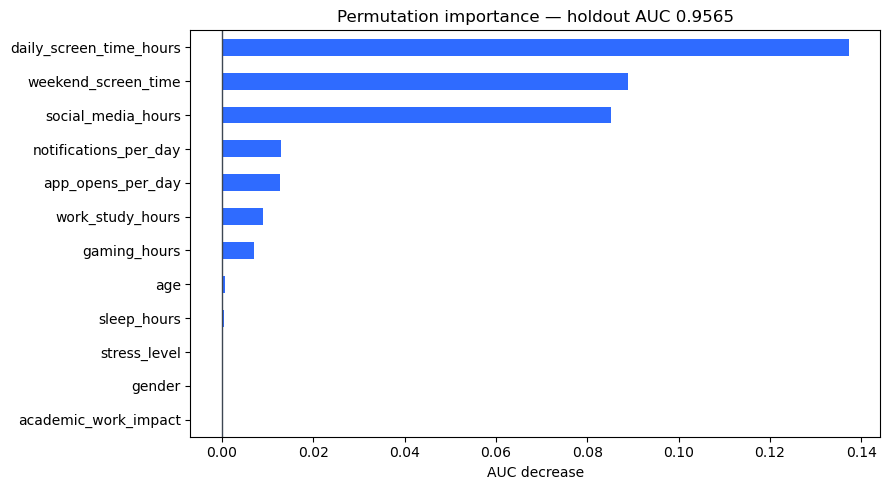

In [6]:
importance = tables['permutation_importance'].sort_values('importance_mean')
display(importance.sort_values('importance_mean', ascending=False).round(5))
ax = importance.plot.barh(x='feature', y='importance_mean', legend=False, figsize=(9, 5), color='#2F6BFF')
ax.axvline(0, color='#3D4652', linewidth=1)
ax.set(title=f"Permutation importance — holdout AUC {quality['holdout_auc_histgb']:.4f}", xlabel='AUC decrease', ylabel='')
plt.tight_layout(); plt.show()

## Takeaways

- ตัวแปรหลักคือเวลาใช้หน้าจอรายวัน, เวลาใช้หน้าจอวันหยุด และเวลา social media
- missingness ค่อนข้างสูงแต่แทบไม่เป็นสัญญาณของ target จึงควรเก็บ missing indicator ไว้และปล่อยให้โมเดลจัดการ
- distribution ของค่าตัวเลข train/test ใกล้กันมาก แต่ missing rate บางคอลัมน์ต่างกันหลาย percentage points
- `id` ต่อเนื่องตามการแบ่ง train/test และ target rate คงที่ตามช่วง id; ไม่ควรใช้ `id` เป็นฟีเจอร์
- baseline แบบ tree ให้ holdout AUC สูง จึงควรต่อยอดด้วย stratified CV และโมเดล boosting ที่รองรับ missing/categorical